# Week 48, Monday lecture: trees and ensembles in one lecture, and the semester in another

**FYS-STK3155/4155, Monday November 23, 2026**

This is the last week. There is no Tuesday session; the lab on Wednesday
November 25, 12:15–16:00, is dedicated to Project 3 (deadline Monday
December 14).

This notebook contains the code behind every figure and number in the Monday
slides (`week48slides.pdf`).

**First lecture — decision trees and ensemble methods (Chapter 7, weeks 46 and 47).**
The whole ladder — a single tree, bagging, a random forest, AdaBoost,
gradient boosting, XGBoost — on two real data sets:

* *Part 1, classification*: the Wisconsin breast-cancer data (the data of
  weeks 41, 46 and 47);
* *Part 2, regression*: the California housing data, with the bias and the
  variance of every step of the ladder measured.

**Second lecture — summary of the semester (weeks 34–47).**

* *Part 3*: the semester in two figures on the Runge function of Project 1 —
  the methods side by side, and the U-shaped test error for four different
  complexity knobs — followed by the week-by-week map of the course;
* *Part 4*: MNIST with trees, next to the numbers of weeks 41 and 44.

Everything needs NumPy, Matplotlib, scikit-learn and `xgboost`
(`pip install xgboost`). Parts 1–3 run in about five minutes; Part 4 (MNIST,
60 000 images) takes about four minutes more and can be switched off. The
palette and the seed (2026) are those of the slides, so every figure here is
the slide figure.

In [1]:
import os
import time
import warnings
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Image, display

BLUE, RED, YELLOW, GREY, GREEN = "#004488", "#BB5566", "#DDAA33", "#777777", "#228833"
SEED = 2026
plt.rcParams.update({"font.size": 11, "axes.spines.top": False, "axes.spines.right": False})

def save(fig, fname):
    fig.savefig(fname)
    fig.savefig(fname.replace(".pdf", ".png"), dpi=150)
    plt.close(fig)


## The ladder, in formulas

**A single tree** (Sections 7.1–7.7) divides the feature space into $J$ boxes
$R_j$ and predicts a constant in each, Eq. (7.1),
$$f(\boldsymbol{x})=\sum_{j=1}^{J}c_j\,I(\boldsymbol{x}\in R_j),$$
the mean of the training responses in the box (regression) or the majority
class (classification). The boxes are found by CART: at a node with $m$ points
try every feature $k$ and threshold $t$ and keep the pair that minimises the
size-weighted impurity of the two children, Eq. (7.9),
$$C(k,t)=\frac{m_{\mathrm{left}}}{m}Q_{\mathrm{left}}+\frac{m_{\mathrm{right}}}{m}Q_{\mathrm{right}},$$
with $Q$ the Gini index $\sum_kp_k(1-p_k)$ (7.7), the entropy
$-\sum_kp_k\log_2p_k$ (7.8), or the node MSE (7.12). A tree is readable,
needs no scaling and finds interactions; it is also piecewise constant and
has a high variance.

**Averaging** (Sections 7.8–7.10). For $B$ predictors with variance
$\sigma^2$ and pairwise correlation $\rho$, Eq. (7.16),
$$\mathrm{var}\Big(\frac1B\sum_bf_b\Big)=\rho\sigma^2+\frac{1-\rho}{B}\sigma^2 .$$
*Bagging* grows $B$ deep trees on bootstrap samples and averages them; the
points left out of each bootstrap sample (a fraction $e^{-1}\approx0.37$,
Eq. (7.17)) give the out-of-bag error. A *random forest* also restricts every
split to $m$ randomly chosen features ($m\approx\sqrt p$ for classification,
$p/3$ for regression, Eq. (7.18)), which lowers $\rho$. Averaging removes
variance and leaves the bias where it was.

**Boosting** (Sections 7.11–7.14) builds an additive model one shallow tree at
a time, Eqs. (7.19)–(7.20),
$$f_m(\boldsymbol{x})=f_{m-1}(\boldsymbol{x})+\nu\,\beta_mT_m(\boldsymbol{x}),$$
each tree chosen to reduce a loss given the previous ones. *AdaBoost* is the
exponential loss: stumps fitted to reweighted data, votes
$\alpha_m=\log[(1-\overline{\mathrm{err}}_m)/\overline{\mathrm{err}}_m]$,
Eqs. (7.26)–(7.29). *Gradient boosting* fits each tree to the pseudo-residuals
$-\partial L/\partial f(\boldsymbol{x}_i)$, Eq. (7.30) — the residuals, for the
squared error. *XGBoost* uses the second derivative as well and penalises the
tree: leaf values $w_j^*=-G_j/(H_j+\lambda)$ and a split gain in closed form,
Eqs. (7.36)–(7.37). Boosting is gradient descent in function space; it
removes bias, and it must be stopped.

## Part 1 — Classification: the Wisconsin breast-cancer data

569 tumours, 30 features computed from images of cell nuclei, two classes
(212 malignant, 357 benign). We use the split of the last two weeks (398
training, 171 test samples; seed 2026, stratified) for accuracy, AUC and
logloss (week 43), and a 5-fold stratified cross-validation repeated ten times
on all 569 samples (week 44).

### 1.1 The ladder is a dictionary

Every method is one line and has the same interface. A linear baseline —
logistic regression on standardised features, in a pipeline so that the
scaler is refitted in every fold — is always in the dictionary. Every
ensemble has $B=200$ trees; nothing is tuned.

In [2]:
def cancer_data():
    """The split of weeks 46 and 47: 398 training and 171 test samples."""
    from sklearn.datasets import load_breast_cancer
    from sklearn.model_selection import train_test_split
    data = load_breast_cancer()
    X, y = data.data, data.target
    Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.3, random_state=SEED, stratify=y)
    return X, y, Xtr, Xte, ytr, yte, data.feature_names


def classification_models(B=200):
    """The ladder, one line per method.  Every ensemble has B trees."""
    import xgboost as xgb
    from sklearn.tree import DecisionTreeClassifier
    from sklearn.ensemble import (BaggingClassifier, RandomForestClassifier, AdaBoostClassifier,
                                  GradientBoostingClassifier)
    from sklearn.linear_model import LogisticRegression
    from sklearn.preprocessing import StandardScaler
    from sklearn.pipeline import make_pipeline
    return {
        "logistic regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000)),
        "tree, depth 3": DecisionTreeClassifier(max_depth=3, random_state=SEED),
        "tree, full depth": DecisionTreeClassifier(random_state=SEED),
        "bagging": BaggingClassifier(DecisionTreeClassifier(), n_estimators=B, oob_score=True,
                                     random_state=SEED),
        "random forest": RandomForestClassifier(n_estimators=B, max_features="sqrt", oob_score=True,
                                                random_state=SEED),
        "AdaBoost, stumps": AdaBoostClassifier(DecisionTreeClassifier(max_depth=1), n_estimators=B,
                                               random_state=SEED),
        "gradient boosting": GradientBoostingClassifier(max_depth=3, learning_rate=0.1, n_estimators=B,
                                                        random_state=SEED),
        "XGBoost": xgb.XGBClassifier(n_estimators=B, learning_rate=0.1, max_depth=3, reg_lambda=1.0,
                                     random_state=SEED, eval_metric="logloss"),
    }


### 1.2 Fit, test split, repeated cross-validation

The same 50 folds are used for every method, so the differences between
methods can be paired fold by fold.

In [3]:
def classification_ladder(B=200, n_repeats=10):
    """Fit the ladder on the training split and evaluate on the test split;
    then repeat with a 5-fold stratified cross-validation, n_repeats times,
    on all 569 samples.  The 5 x n_repeats fold accuracies also give paired
    differences against logistic regression (same folds for every method)."""
    from sklearn.metrics import roc_auc_score, log_loss, roc_curve, confusion_matrix
    from sklearn.model_selection import RepeatedStratifiedKFold, cross_val_score
    X, y, Xtr, Xte, ytr, yte, names = cancer_data()
    models = classification_models(B)
    cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=n_repeats, random_state=SEED)
    res, roc, fitted = {}, {}, {}
    print("\nWisconsin breast cancer, %d train / %d test, %d features, B = %d trees" %
          (len(ytr), len(yte), X.shape[1], B))
    print("  %-22s train   test    AUC     logloss  oob     CV mean +- std (5 x %d folds)" % ("", n_repeats))
    for k, m in models.items():
        m.fit(Xtr, ytr)
        p = m.predict_proba(Xte)[:, 1]
        scores = cross_val_score(m, X, y, cv=cv, n_jobs=-1)
        res[k] = dict(train=m.score(Xtr, ytr), test=m.score(Xte, yte), auc=roc_auc_score(yte, p),
                      logloss=log_loss(yte, p), oob=getattr(m, "oob_score_", np.nan),
                      cv=scores, confusion=confusion_matrix(yte, m.predict(Xte)))
        roc[k] = roc_curve(yte, p)
        fitted[k] = m
        r = res[k]
        print(f"  {k:22s} {r['train']:.4f}  {r['test']:.4f}  {r['auc']:.4f}  {r['logloss']:.4f}  "
              f"{r['oob']:.4f}  {scores.mean():.4f} +- {scores.std():.4f}")
    ref = res["logistic regression"]["cv"]
    print("  paired differences in CV accuracy against logistic regression (mean, standard error over folds):")
    for k in models:
        if k != "logistic regression":
            d = res[k]["cv"] - ref
            print(f"    {k:22s} {d.mean():+.4f} +- {d.std(ddof=1) / np.sqrt(len(d)):.4f}")
    d = res["AdaBoost, stumps"]["cv"] - res["random forest"]["cv"]
    print(f"  AdaBoost minus random forest, paired over the folds: {d.mean():+.4f} "
          f"(std of the differences {d.std(ddof=1):.4f})")
    # class 0 is malignant, class 1 benign: rows of the confusion matrix are the true classes
    for k in ("tree, full depth", "random forest", "gradient boosting", "logistic regression"):
        (mm, mb), (bm, bb) = res[k]["confusion"]
        print(f"  test split, {k:20s}: of {mm + mb} malignant {mb} are missed (called benign); "
              f"of {bm + bb} benign {bm} are false alarms")
    return res, roc, fitted, (Xtr, Xte, ytr, yte)


In [4]:
res_c, roc_c, fitted_c, (Xtr_c, Xte_c, ytr_c, yte_c) = classification_ladder(B=200, n_repeats=10)


Wisconsin breast cancer, 398 train / 171 test, 30 features, B = 200 trees
                         train   test    AUC     logloss  oob     CV mean +- std (5 x 10 folds)


  logistic regression    0.9925  0.9649  0.9924  0.0934  nan  0.9782 +- 0.0134
  tree, depth 3          0.9774  0.9181  0.9217  1.4366  nan  0.9255 +- 0.0229


  tree, full depth       1.0000  0.9298  0.9345  2.5294  nan  0.9225 +- 0.0274


  bagging                1.0000  0.9415  0.9748  0.5237  0.9548  0.9583 +- 0.0199


  random forest          1.0000  0.9532  0.9798  0.3318  0.9573  0.9594 +- 0.0177


  AdaBoost, stumps       1.0000  0.9474  0.9907  0.4424  nan  0.9721 +- 0.0154


  gradient boosting      1.0000  0.9532  0.9879  0.2378  nan  0.9643 +- 0.0197


  XGBoost                1.0000  0.9474  0.9855  0.1380  nan  0.9685 +- 0.0163
  paired differences in CV accuracy against logistic regression (mean, standard error over folds):
    tree, depth 3          -0.0527 +- 0.0033
    tree, full depth       -0.0557 +- 0.0040
    bagging                -0.0199 +- 0.0030
    random forest          -0.0188 +- 0.0030
    AdaBoost, stumps       -0.0062 +- 0.0025
    gradient boosting      -0.0139 +- 0.0029
    XGBoost                -0.0097 +- 0.0026
  AdaBoost minus random forest, paired over the folds: +0.0127 (std of the differences 0.0164)
  test split, tree, full depth    : of 64 malignant 3 are missed (called benign); of 107 benign 9 are false alarms
  test split, random forest       : of 64 malignant 4 are missed (called benign); of 107 benign 4 are false alarms
  test split, gradient boosting   : of 64 malignant 3 are missed (called benign); of 107 benign 5 are false alarms
  test split, logistic regression : of 64 malignant 4 are missed (c

**Reading the table.**

* *One tree → many trees* is the big step: the cross-validated accuracy goes
  from $0.92$–$0.93$ to $0.96$. A deeper single tree does not help; depth 3
  and full depth are equal within the noise.
* *Forest against bagging*: a small gain — the correlation between the trees
  only fell from $0.81$ to $0.78$ (week 46). The out-of-bag accuracies
  ($0.955$, $0.957$) reproduce the cross-validation numbers for free.
* *Boosting* is on top among the trees ($0.964$–$0.972$), with stumps:
  additive effects of single features are enough here.
* *Logistic regression wins* ($0.978$). The classes are close to linearly
  separable in the 30 scaled features, and a model with 31 parameters and low
  variance is the right tool for 569 samples.
* *Accuracy is not the whole story.* Logloss: full tree $2.53$ (a tree that is
  wrong is wrong with probability one), forest $0.33$, XGBoost $0.14$,
  logistic regression $0.09$. AdaBoost has AUC $0.991$ and logloss $0.44$: it
  ranks the samples well, but its scores are not calibrated probabilities.
* On the test split every method misses 3 or 4 of the 64 malignant tumours at
  threshold $0.5$; they differ in the false alarms among the 107 benign ones
  (9 for the tree, 4 for the forest, 2 for logistic regression).
* The split alone cannot rank the ensembles: one test sample is $1/171=0.006$
  and the binomial standard error of an accuracy of $0.95$ on 171 samples is
  $0.017$. The random forest is ahead of AdaBoost on the split ($0.953$
  against $0.947$) and behind it by $0.013$ in the cross-validation.

### 1.3 Error against the number of trees, and the figure

In [5]:
def staged_test_error(fitted, Xte, yte):
    """Test error after 1, 2, ..., B trees for the four ensembles.  Bagging and
    the forest average the class probabilities of their first b trees;
    AdaBoost and gradient boosting have staged_predict."""
    out = {}
    for k in ("bagging", "random forest"):
        m = fitted[k]
        if k == "bagging":
            P = np.array([t.predict_proba(Xte[:, f])[:, 1] for t, f in zip(m.estimators_, m.estimators_features_)])
        else:
            P = np.array([t.predict_proba(Xte)[:, 1] for t in m.estimators_])
        run = np.cumsum(P, axis=0) / np.arange(1, len(P) + 1)[:, None]
        out[k] = np.mean((run > 0.5).astype(int) != yte, axis=1)
    for k in ("AdaBoost, stumps", "gradient boosting"):
        out[k] = np.array([np.mean(p != yte) for p in fitted[k].staged_predict(Xte)])
    return out


def fig_cancer(res, roc, staged, fname="week48_cancer.pdf"):
    cols = {"logistic regression": GREY, "tree, depth 3": YELLOW, "tree, full depth": YELLOW,
            "bagging": GREEN, "random forest": GREEN, "AdaBoost, stumps": RED,
            "gradient boosting": BLUE, "XGBoost": BLUE}
    fig, ax = plt.subplots(1, 3, figsize=(11.5, 4.7), gridspec_kw={"width_ratios": [1.3, 1, 1.1]})
    keys = list(res)[::-1]
    for i, k in enumerate(keys):
        s = res[k]["cv"]
        ax[0].errorbar(s.mean(), i, xerr=s.std(), fmt="o", color=cols[k], capsize=3, ms=6)
        ax[0].plot(res[k]["test"], i, "D", mfc="none", mec=cols[k], ms=6)
    ax[0].set_yticks(range(len(keys)))
    ax[0].set_yticklabels(keys, fontsize=10.5)
    ax[0].set_xlabel("accuracy")
    ax[0].set_title("(a) filled: 5-fold CV, mean $\\pm$ std over 50 folds;\nopen: the single test split",
                    fontsize=11)
    for k, ls in [("tree, full depth", "-"), ("random forest", "-"), ("AdaBoost, stumps", "-"),
                  ("gradient boosting", "-"), ("logistic regression", "--")]:
        fpr, tpr, _ = roc[k]
        ax[1].plot(fpr, tpr, ls, color=cols[k], lw=1.5, label=f"{k} ({res[k]['auc']:.3f})")
    ax[1].set_xlim(-0.01, 0.4)
    ax[1].set_ylim(0.6, 1.01)
    ax[1].set_xlabel("false positive rate")
    ax[1].set_ylabel("true positive rate")
    ax[1].set_title("(b) ROC curves on the\ntest split (AUC)", fontsize=11)
    ax[1].legend(fontsize=9.5, frameon=False, loc="lower right")
    for k, ls in [("bagging", "--"), ("random forest", "-"), ("AdaBoost, stumps", "-"),
                  ("gradient boosting", "-")]:
        e = staged[k]
        ax[2].plot(np.arange(1, len(e) + 1), e, ls, color=cols[k], lw=1.4, label=k)
    ax[2].axhline(1 - res["logistic regression"]["test"], color=GREY, ls=":", lw=1)
    ax[2].text(0.98, 1 - res["logistic regression"]["test"] - 0.001, "logistic regression", color=GREY,
               fontsize=9.5, va="top", ha="right", transform=ax[2].get_yaxis_transform())
    ax[2].set_xscale("log")
    ax[2].set_xlabel("number of trees")
    ax[2].set_ylabel("test error")
    ax[2].set_ylim(0.02, 0.16)
    ax[2].set_title("(c) test error against\nthe number of trees", fontsize=11)
    ax[2].legend(fontsize=9.5, frameon=False)
    fig.tight_layout()
    save(fig, fname)


bagging           : 1 tree 0.0994, 10 trees 0.0760, 50 trees 0.0585, 200 trees 0.0585
random forest     : 1 tree 0.1111, 10 trees 0.0351, 50 trees 0.0409, 200 trees 0.0468
AdaBoost, stumps  : 1 tree 0.1404, 10 trees 0.0760, 50 trees 0.0468, 200 trees 0.0526
gradient boosting : 1 tree 0.3743, 10 trees 0.0643, 50 trees 0.0643, 200 trees 0.0468


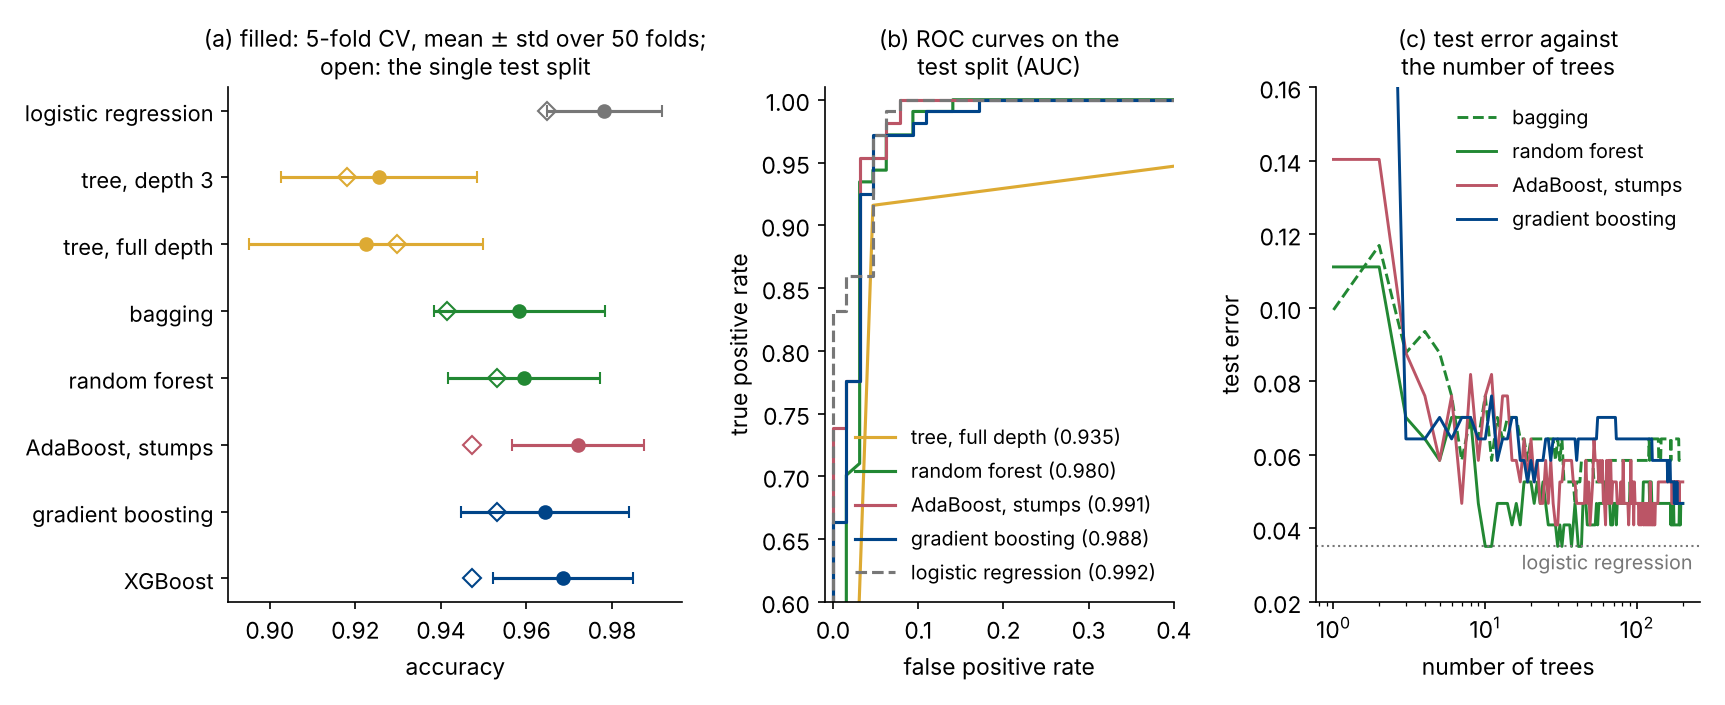

In [6]:
staged_c = staged_test_error(fitted_c, Xte_c, yte_c)
for k, e in staged_c.items():
    print(f"{k:18s}: 1 tree {e[0]:.4f}, 10 trees {e[9]:.4f}, 50 trees {e[49]:.4f}, 200 trees {e[-1]:.4f}")
fig_cancer(res_c, roc_c, staged_c, "week48_cancer.png")
display(Image("week48_cancer.png"))

(a) Filled symbols: mean and standard deviation of the accuracy over the 50
folds; open diamonds: the single test split. The error bars are as large as
the steps between neighbours on the ladder. (b) A full tree outputs only 0
or 1 and its ROC curve has a single interior point; the ensembles output
graded probabilities. (c) After ten to fifty trees every ensemble has done
most of what it can do on these data; after that the curves move by one test
sample at a time.

## Part 2 — Regression: the California housing data

20 640 districts (census block groups) of the 1990 US census in California
(Pace and Barry, 1997; the example of Chapter 10 of Hastie, Tibshirani and
Friedman). The target is the median house value of the district in units of
100 000 dollars — mean $2.07$, standard deviation $1.15$, capped at $5$, a
value that $4.8\,\%$ of the districts reach. Eight numerical features: median
income `MedInc`, median house age `HouseAge`, rooms and bedrooms per household
`AveRooms` and `AveBedrms`, `Population`, persons per household `AveOccup`,
`Latitude` and `Longitude`.

scikit-learn downloads the data on first use (`fetch_california_housing`). We
set aside 25 % (5 160 districts) as the test set and use it once; everything
that is tuned is tuned on the training data.

In [7]:
def housing_data():
    """20 640 census block groups ('districts') of the 1990 California census;
    eight features, the target is the median house value of the district in
    units of 100 000 dollars (capped at 5.00001).  Split: 75 % / 25 %."""
    from sklearn.datasets import fetch_california_housing
    from sklearn.model_selection import train_test_split
    data = fetch_california_housing()
    X, y = data.data, data.target
    Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.25, random_state=SEED)
    return X, y, Xtr, Xte, ytr, yte, list(data.feature_names)


def rmse(y, f):
    return float(np.sqrt(np.mean((y - f)**2)))


def r2(y, f):
    return float(1.0 - np.sum((y - f)**2) / np.sum((y - np.mean(y))**2))


### 2.1 The data on the map, and the boxes of a tree

(a) The median house value on the map. (b) A regression tree with twelve
leaves grown on longitude and latitude alone: recursive binary splitting,
drawn on the map. (c) The strongest single feature, the median income, with a
straight line and a depth-3 tree.

In [8]:
def fig_housing_data(fname="week48_housing_data.pdf", n_leaves=12):
    """(a) the map, (b) recursive binary splitting on the map: a regression
    tree with n_leaves leaves grown on longitude and latitude alone, (c) the
    house value against the median income with a straight line and a depth-3
    tree on that single feature."""
    from sklearn.tree import DecisionTreeRegressor
    from sklearn.linear_model import LinearRegression
    X, y, Xtr, Xte, ytr, yte, names = housing_data()
    lon, lat, inc = names.index("Longitude"), names.index("Latitude"), names.index("MedInc")
    rng = np.random.default_rng(SEED)
    show = rng.choice(len(ytr), 6000, replace=False)
    fig, ax = plt.subplots(1, 3, figsize=(11.5, 4.7), gridspec_kw={"width_ratios": [1, 1, 1.05]})
    sc = ax[0].scatter(Xtr[show, lon], Xtr[show, lat], c=ytr[show], s=3, cmap="viridis", vmin=0.5, vmax=5)
    ax[0].set_title("(a) median house value of a district\n(units of 100 000 dollars)", fontsize=11)
    fig.colorbar(sc, ax=ax[0], fraction=0.046, pad=0.02)
    tree = DecisionTreeRegressor(max_leaf_nodes=n_leaves, random_state=SEED).fit(Xtr[:, [lon, lat]], ytr)
    t = tree.tree_
    x0, x1, y0, y1 = Xtr[:, lon].min(), Xtr[:, lon].max(), Xtr[:, lat].min(), Xtr[:, lat].max()

    def boxes(node, box):
        if t.children_left[node] == -1:
            return [(box, t.value[node][0, 0])]
        f, s = t.feature[node], t.threshold[node]
        left, right = list(box), list(box)
        if f == 0:
            left[1], right[0] = s, s
        else:
            left[3], right[2] = s, s
        return boxes(t.children_left[node], left) + boxes(t.children_right[node], right)

    leaves = boxes(0, [x0, x1, y0, y1])
    cmap = plt.get_cmap("viridis")
    for (a, b, c, d), v in leaves:
        ax[1].add_patch(plt.Rectangle((a, c), b - a, d - c, fc=cmap((v - 0.5) / 4.5), ec="white", lw=1.2,
                                      alpha=0.85))
        if (b - a) > 0.6 and (d - c) > 0.45:
            ax[1].text((a + b) / 2, (c + d) / 2, f"{v:.2f}", ha="center", va="center", fontsize=9.5,
                       color="white" if v < 3.2 else "black")
    ax[1].scatter(Xtr[show[:1500], lon], Xtr[show[:1500], lat], s=1, color="black", alpha=0.25)
    ax[1].set_xlim(x0, x1)
    ax[1].set_ylim(y0, y1)
    ax[1].set_title(f"(b) a tree on (longitude, latitude) only:\n{n_leaves} boxes, each predicting its mean",
                    fontsize=11)
    for a in ax[:2]:
        a.set_xticks([-124, -122, -120, -118, -116])
        a.set_xlabel("longitude")
        a.set_ylabel("latitude")
    ax[2].scatter(Xtr[show, inc], ytr[show], s=2, color=GREY, alpha=0.35)
    xg = np.linspace(0.5, 12, 400)[:, None]
    lin = LinearRegression().fit(Xtr[:, [inc]], ytr)
    stump = DecisionTreeRegressor(max_depth=3, random_state=SEED).fit(Xtr[:, [inc]], ytr)
    ax[2].plot(xg, lin.predict(xg), color=RED, lw=1.6, label="straight line")
    ax[2].plot(xg, stump.predict(xg), color=BLUE, lw=1.6, label="tree, depth 3")
    ax[2].set_xlim(0, 12)
    ax[2].set_ylim(0, 5.4)
    ax[2].set_xlabel("median income of the district (10 000 dollars)")
    ax[2].set_ylabel("median house value")
    ax[2].set_title("(c) the strongest single feature;\nnote the cap at 5", fontsize=11)
    ax[2].legend(fontsize=10, frameon=False, loc="lower right")
    fig.tight_layout()
    save(fig, fname)
    f2 = tree.predict(Xte[:, [lon, lat]])
    out = dict(map_tree_r2=r2(yte, f2), income_line_r2=r2(yte, lin.predict(Xte[:, [inc]])),
               income_tree_r2=r2(yte, stump.predict(Xte[:, [inc]])),
               first_split=(["Longitude", "Latitude"][t.feature[0]], float(t.threshold[0])),
               capped=float(np.mean(y >= 5.0)))
    print(f"\nCalifornia housing: {X.shape[0]} districts, {X.shape[1]} features, "
          f"{len(ytr)} train / {len(yte)} test; mean value {y.mean():.3f}, std {y.std():.3f}, "
          f"fraction at the cap {out['capped']:.3f}")
    print(f"  tree on (longitude, latitude), {n_leaves} leaves: first split {out['first_split'][0]} <= "
          f"{out['first_split'][1]:.2f}, test R2 {out['map_tree_r2']:.3f}")
    print(f"  median income alone: straight line R2 {out['income_line_r2']:.3f}, depth-3 tree R2 "
          f"{out['income_tree_r2']:.3f}")
    return out



California housing: 20640 districts, 8 features, 15480 train / 5160 test; mean value 2.069, std 1.154, fraction at the cap 0.048
  tree on (longitude, latitude), 12 leaves: first split Latitude <= 37.93, test R2 0.428
  median income alone: straight line R2 0.479, depth-3 tree R2 0.478


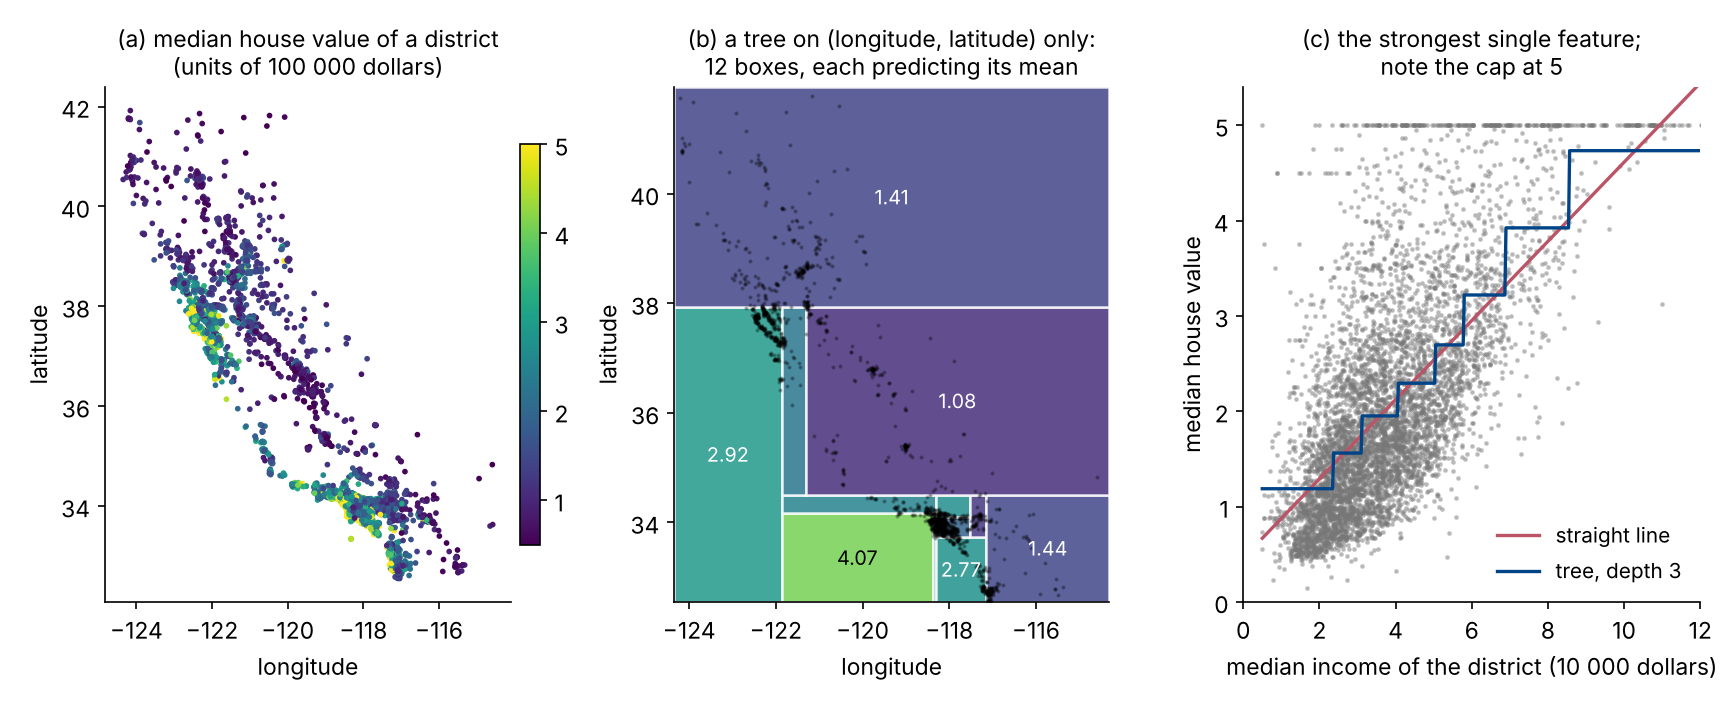

In [9]:
out_map = fig_housing_data("week48_housing_data.png")
display(Image("week48_housing_data.png"))

The first cut is latitude $\le37.93$ (north of the San Francisco Bay area
against the rest); twelve boxes already find the two metropolitan areas and
explain $43\,\%$ of the variance from the position alone. No function of the
longitude *or* the latitude alone could do that: the position enters through
an interaction of two features, which a tree represents as a split inside a
split. The income alone gives $R^2=0.48$, with the line and with the tree.

### 2.2 The ladder

Ordinary least squares on standardised features as the reference; a single
tree with its depth chosen by 5-fold cross-validation on the training data,
and a fully grown tree; bagging and a random forest with 200 trees ($m=3$
features per split); gradient boosting with trees of depth 3 and 6
($\nu=0.1$, $M=200$); XGBoost with $\nu=0.05$, row and column subsampling,
and early stopping on a validation part ($20\,\%$) of the training data.

In [10]:
def regression_ladder(B=200):
    """The ladder on the housing data.  Everything that is tuned is tuned on
    the training data (cross-validation for the tree, a validation split for
    the early stopping of XGBoost); the test set is used once, at the end."""
    import xgboost as xgb
    from sklearn.tree import DecisionTreeRegressor
    from sklearn.ensemble import BaggingRegressor, RandomForestRegressor, GradientBoostingRegressor
    from sklearn.linear_model import LinearRegression
    from sklearn.preprocessing import StandardScaler
    from sklearn.pipeline import make_pipeline
    from sklearn.model_selection import GridSearchCV, train_test_split
    X, y, Xtr, Xte, ytr, yte, names = housing_data()
    res, fitted = {}, {}

    def report(k, m, dt, extra=""):
        res[k] = dict(train=rmse(ytr, m.predict(Xtr)), test=rmse(yte, m.predict(Xte)),
                      r2=r2(yte, m.predict(Xte)), time=dt, oob=getattr(m, "oob_score_", np.nan))
        fitted[k] = m
        r = res[k]
        print(f"  {k:36s} train RMSE {r['train']:.3f}  test RMSE {r['test']:.3f}  R2 {r['r2']:.3f}  "
              f"({dt:5.1f} s){extra}")

    print("\nCalifornia housing, the ladder (RMSE in units of 100 000 dollars):")
    t0 = time.time()
    m = make_pipeline(StandardScaler(), LinearRegression()).fit(Xtr, ytr)
    report("linear regression (OLS)", m, time.time() - t0)
    t0 = time.time()
    grid = GridSearchCV(DecisionTreeRegressor(random_state=SEED), {"max_depth": list(range(2, 21))},
                        cv=5, scoring="neg_mean_squared_error", n_jobs=-1).fit(Xtr, ytr)
    depth = grid.best_params_["max_depth"]
    report(f"tree, depth {depth} (5-fold CV)", grid.best_estimator_, time.time() - t0,
           f"  leaves {grid.best_estimator_.get_n_leaves()}")
    t0 = time.time()
    m = DecisionTreeRegressor(random_state=SEED).fit(Xtr, ytr)
    report("tree, full depth", m, time.time() - t0, f"  depth {m.get_depth()}, leaves {m.get_n_leaves()}")
    t0 = time.time()
    m = BaggingRegressor(DecisionTreeRegressor(), n_estimators=B, oob_score=True, n_jobs=-1,
                         random_state=SEED).fit(Xtr, ytr)
    report("bagging", m, time.time() - t0, f"  oob R2 {m.oob_score_:.3f}")
    t0 = time.time()
    m = RandomForestRegressor(n_estimators=B, max_features=3, oob_score=True, n_jobs=-1,
                              random_state=SEED).fit(Xtr, ytr)
    report("random forest, m = 3", m, time.time() - t0, f"  oob R2 {m.oob_score_:.3f}")
    t0 = time.time()
    m = GradientBoostingRegressor(max_depth=3, learning_rate=0.1, n_estimators=B, random_state=SEED).fit(Xtr, ytr)
    report(f"gradient boosting, depth 3, M = {B}", m, time.time() - t0)
    t0 = time.time()
    m = GradientBoostingRegressor(max_depth=6, learning_rate=0.1, n_estimators=B, random_state=SEED).fit(Xtr, ytr)
    report(f"gradient boosting, depth 6, M = {B}", m, time.time() - t0)
    # XGBoost: many small steps, stopped on a validation split of the training data
    t0 = time.time()
    Xa, Xv, ya, yv = train_test_split(Xtr, ytr, test_size=0.2, random_state=SEED)
    m = xgb.XGBRegressor(n_estimators=5000, learning_rate=0.05, max_depth=6, subsample=0.8,
                         colsample_bytree=0.8, reg_lambda=1.0, early_stopping_rounds=50,
                         random_state=SEED, n_jobs=2)
    m.fit(Xa, ya, eval_set=[(Xv, yv)], verbose=False)
    report("XGBoost, depth 6, early stopping", m, time.time() - t0, f"  stopped at M = {m.best_iteration + 1}")
    res["_depth"] = depth
    res["_cv_curve"] = (list(range(2, 21)), np.sqrt(-grid.cv_results_["mean_test_score"]))
    res["_xgb_M"] = m.best_iteration + 1
    return res, fitted, (Xtr, Xte, ytr, yte, names)


In [11]:
res_h, fitted_h, data_h = regression_ladder(B=200)


California housing, the ladder (RMSE in units of 100 000 dollars):
  linear regression (OLS)              train RMSE 0.728  test RMSE 0.713  R2 0.618  (  0.0 s)


  tree, depth 10 (5-fold CV)           train RMSE 0.480  test RMSE 0.647  R2 0.686  (  2.6 s)  leaves 707
  tree, full depth                     train RMSE 0.000  test RMSE 0.718  R2 0.613  (  0.1 s)  depth 37, leaves 14871


  bagging                              train RMSE 0.187  test RMSE 0.507  R2 0.807  (  8.3 s)  oob R2 0.807


  random forest, m = 3                 train RMSE 0.181  test RMSE 0.491  R2 0.819  (  3.2 s)  oob R2 0.819


  gradient boosting, depth 3, M = 200  train RMSE 0.465  test RMSE 0.504  R2 0.809  (  4.6 s)


  gradient boosting, depth 6, M = 200  train RMSE 0.293  test RMSE 0.467  R2 0.836  (  8.9 s)


  XGBoost, depth 6, early stopping     train RMSE 0.281  test RMSE 0.453  R2 0.846  (  1.8 s)  stopped at M = 703


**Reading the table.**

* A *fully grown tree* (14 871 leaves, nearly one per training district)
  reproduces the training data and is no better than a straight line on new
  districts ($0.718$ against $0.713$). The *best single tree* (depth 10, 707
  leaves) gains a little ($0.647$).
* *Averaging 200 deep trees* takes the same deep trees from $0.718$ to
  $0.507$; the forest reaches $0.491$. The out-of-bag $R^2$ equals the test
  $R^2$ to three digits.
* *Boosting* with trees of depth 6 goes further: $0.467$, and $0.453$ for
  XGBoost with early stopping — a typical error of 45 000 dollars against
  71 000 for the linear model, or a factor $2.5$ in mean squared error
  ($0.508\to0.205$).
* On the cancer data the linear model won; here it loses clearly. Which
  method is best is a property of the data.

### 2.3 Error against the number of trees

In [12]:
def staged_test_rmse(fitted, Xte, yte):
    out = {}
    for k in fitted:
        m = fitted[k]
        if k in ("bagging", "random forest, m = 3"):
            P = np.array([t.predict(Xte) for t in m.estimators_])
            run = np.cumsum(P, axis=0) / np.arange(1, len(P) + 1)[:, None]
            out[k] = np.sqrt(np.mean((run - yte)**2, axis=1))
        elif k.startswith("gradient boosting"):
            out[k] = np.array([rmse(yte, f) for f in m.staged_predict(Xte)])
        elif k.startswith("XGBoost"):
            Ms = np.unique(np.round(np.logspace(0, np.log10(m.best_iteration + 1), 40)).astype(int))
            out[k] = (Ms, np.array([rmse(yte, m.predict(Xte, iteration_range=(0, int(M)))) for M in Ms]))
    return out


def fig_housing_ladder(res, fitted, staged, data, fname="week48_housing_ladder.pdf"):
    Xtr, Xte, ytr, yte, names = data
    keys = [k for k in res if not k.startswith("_")]
    col = lambda k: (GREY if "linear" in k else YELLOW if k.startswith("tree") else
                     GREEN if ("bagging" in k or "forest" in k) else BLUE)
    fig, ax = plt.subplots(1, 3, figsize=(11.5, 4.7), gridspec_kw={"width_ratios": [1.35, 1.1, 1]})
    for i, k in enumerate(keys[::-1]):
        ax[0].barh(i, res[k]["test"], color=col(k), height=0.62)
        ax[0].plot(res[k]["train"], i, "|", color="black", ms=11, mew=1.5)
        ax[0].text(max(res[k]["test"], res[k]["train"]) + 0.012, i, f"{res[k]['test']:.3f}", va="center",
                   fontsize=10)
    ax[0].set_yticks(range(len(keys)))
    ax[0].set_yticklabels([k.replace(", early stopping", "\nearly stopping").replace(" (5-fold CV)", "\n(5-fold CV)")
                           .replace("gradient boosting, ", "gradient boosting\n") for k in keys[::-1]], fontsize=10)
    ax[0].set_xlim(0, 0.86)
    ax[0].set_xlabel("RMSE (100 000 dollars)")
    ax[0].set_title("(a) bars: test RMSE;\nblack ticks: training RMSE", fontsize=11)
    for k, ls, c in [("bagging", "--", GREEN), ("random forest, m = 3", "-", GREEN)]:
        ax[1].plot(np.arange(1, len(staged[k]) + 1), staged[k], ls, color=c, lw=1.4, label=k.split(",")[0])
    kk = [k for k in staged if k.startswith("gradient boosting")]
    ax[1].plot(np.arange(1, len(staged[kk[0]]) + 1), staged[kk[0]], "-", color=RED, lw=1.4, label="boosting, depth 3")
    ax[1].plot(np.arange(1, len(staged[kk[1]]) + 1), staged[kk[1]], "-", color=BLUE, lw=1.4, label="boosting, depth 6")
    kx = [k for k in staged if k.startswith("XGBoost")][0]
    ax[1].plot(*staged[kx], ":", color=BLUE, lw=1.6, label="XGBoost, depth 6")
    ax[1].axhline(res["linear regression (OLS)"]["test"], color=GREY, ls=":", lw=1)
    ax[1].text(0.98, res["linear regression (OLS)"]["test"] + 0.008, "linear regression", color=GREY,
               fontsize=9.5, ha="right", transform=ax[1].get_yaxis_transform())
    ax[1].set_xscale("log")
    ax[1].set_ylim(0.4, 1.0)
    ax[1].set_xlabel("number of trees")
    ax[1].set_ylabel("test RMSE")
    ax[1].set_title("(b) averaging saturates,\nboosting keeps learning", fontsize=11)
    ax[1].legend(fontsize=8.5, frameon=False, loc="upper right", handlelength=1.6)
    f = fitted[kx].predict(Xte)
    hb = ax[2].hexbin(yte, f, gridsize=45, cmap="Blues", bins="log", mincnt=1, extent=(0, 5.2, 0, 5.8))
    ax[2].plot([0, 5.2], [0, 5.2], color=RED, lw=1)
    ax[2].set_xlabel("true median house value")
    ax[2].set_ylabel("predicted")
    ax[2].set_title(f"(c) XGBoost on the test set,\n$R^2={res[kx]['r2']:.3f}$", fontsize=11)
    fig.tight_layout()
    save(fig, fname)


bagging                             : 1 tree 0.759, 10 trees 0.539, 50 trees 0.513, 200 trees 0.507
random forest, m = 3                : 1 tree 0.769, 10 trees 0.531, 50 trees 0.497, 200 trees 0.491
gradient boosting, depth 3, M = 200 : 1 tree 1.095, 10 trees 0.804, 50 trees 0.567, 200 trees 0.504
gradient boosting, depth 6, M = 200 : 1 tree 1.080, 10 trees 0.709, 50 trees 0.501, 200 trees 0.467


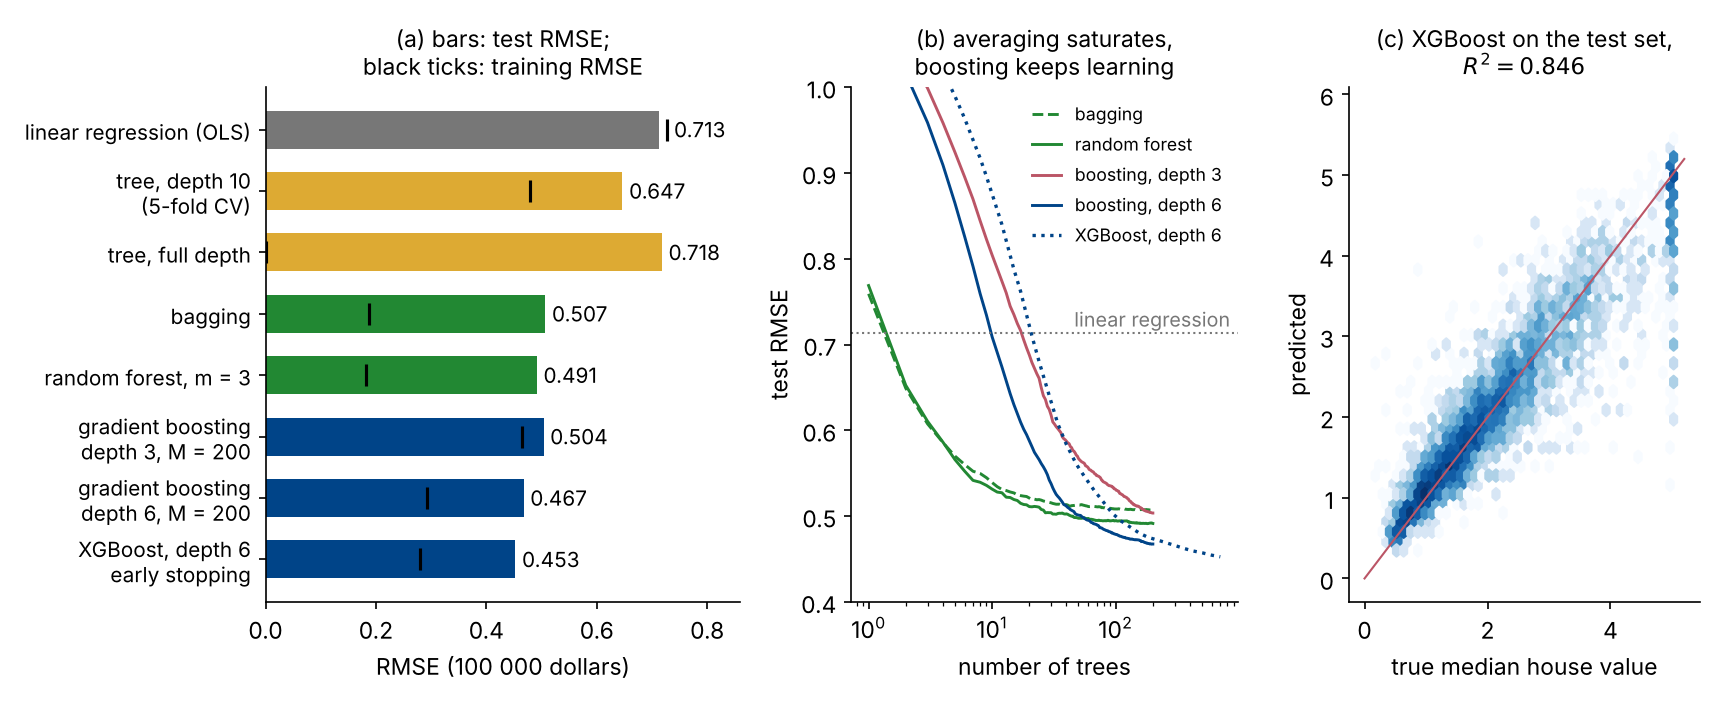

In [13]:
staged_h = staged_test_rmse(fitted_h, data_h[1], data_h[3])
for k, e in staged_h.items():
    if not isinstance(e, tuple):
        print(f"{k:36s}: 1 tree {e[0]:.3f}, 10 trees {e[9]:.3f}, 50 trees {e[49]:.3f}, 200 trees {e[-1]:.3f}")
fig_housing_ladder(res_h, fitted_h, staged_h, data_h, "week48_housing_ladder.png")
display(Image("week48_housing_ladder.png"))

(a) Bars are test errors, black ticks training errors: bagging and the forest
fit the training data almost perfectly and still generalise; boosting with
depth 3 hardly overfits at all. (b) Bagging and the forest are flat after
about fifty trees; boosting starts from the mean (RMSE $1.1$), passes them,
and is still falling at 200 trees. (c) Predicted against true value on the
test set; the vertical stripe at 5 is the cap of the target.

### 2.4 Bias and variance of every step of the ladder, measured

The decomposition of week 36, Eq. (2.52), measured directly: 30 training sets
of 3 000 districts are drawn from the training pool, every method is fitted
on each of them and predicts the same 2 000 test districts. With $\bar f$ the
prediction averaged over the training sets,
$$\overline{(y-f)^2}=\overline{(y-\bar f)^2}+\overline{(f-\bar f)^2},$$
the first term being bias$^2$ plus noise and the second the variance. (About
two minutes.)

In [14]:
def bias_variance_housing(n_rep=30, n_train=3000, n_test=2000, B=50, fname="week48_housing_biasvar.pdf"):
    """The bias-variance decomposition of week 36, measured: n_rep training
    sets of n_train districts each are drawn from the training pool, every
    method is fitted on each of them and predicts the same n_test test
    districts.  With f_bar the average prediction over the training sets,
        error = mean (y - f)^2 = mean (y - f_bar)^2 + mean (f - f_bar)^2,
    the first term being bias^2 + noise and the second the variance."""
    from sklearn.tree import DecisionTreeRegressor
    from sklearn.ensemble import BaggingRegressor, RandomForestRegressor, GradientBoostingRegressor
    from sklearn.linear_model import LinearRegression
    X, y, Xtr, Xte, ytr, yte, names = housing_data()
    Xt, yt = Xte[:n_test], yte[:n_test]
    rng = np.random.default_rng(SEED)
    depths = [1, 2, 3, 4, 5, 6, 8, 10, 12, 15, 20, None]
    make = {f"depth {d}": (lambda d=d: DecisionTreeRegressor(max_depth=d)) for d in depths}
    make.update({
        "linear regression": lambda: LinearRegression(),
        "single deep tree": lambda: DecisionTreeRegressor(),
        "bagging": lambda: BaggingRegressor(DecisionTreeRegressor(), n_estimators=B, n_jobs=-1),
        "random forest": lambda: RandomForestRegressor(n_estimators=B, max_features=3, n_jobs=-1),
        "boosted stumps": lambda: GradientBoostingRegressor(max_depth=1, learning_rate=0.1, n_estimators=300),
        "gradient boosting": lambda: GradientBoostingRegressor(max_depth=4, learning_rate=0.1, n_estimators=300),
    })
    P = {k: np.zeros((n_rep, n_test)) for k in make}
    for r in range(n_rep):
        idx = rng.choice(len(ytr), n_train, replace=False)
        for k, f in make.items():
            m = f()
            if hasattr(m, "random_state"):
                m.set_params(random_state=int(rng.integers(1 << 30)))
            P[k][r] = m.fit(Xtr[idx], ytr[idx]).predict(Xt)
    out = {}
    for k in make:
        fbar = P[k].mean(axis=0)
        out[k] = (np.mean((yt - P[k])**2), np.mean((yt - fbar)**2), np.mean((P[k] - fbar)**2))
    print(f"\nBias-variance on the housing data ({n_rep} training sets of {n_train}, {n_test} test districts):")
    print("  %-20s error   bias^2+noise  variance" % "")
    for k, (e, b, v) in out.items():
        print(f"  {k:20s} {e:.4f}  {b:.4f}        {v:.4f}")

    fig, ax = plt.subplots(1, 2, figsize=(11.5, 4.3), gridspec_kw={"width_ratios": [1, 1.25]})
    xs = np.arange(len(depths))
    E = np.array([out[f"depth {d}"] for d in depths])
    ax[0].plot(xs, E[:, 0], "o-", color="black", label="test error")
    ax[0].plot(xs, E[:, 1], "s--", color=BLUE, label="bias$^2$ + noise")
    ax[0].plot(xs, E[:, 2], "^--", color=RED, label="variance")
    ax[0].set_xticks(xs)
    ax[0].set_xticklabels([str(d) if d else "full" for d in depths], fontsize=10)
    ax[0].set_xlabel("depth of a single tree")
    ax[0].set_ylabel("mean squared error")
    ax[0].set_title("(a) one tree: the bias falls, the variance rises", fontsize=11)
    ax[0].legend(fontsize=10, frameon=False)
    keys = ["linear regression", "single deep tree", "bagging", "random forest", "boosted stumps",
            "gradient boosting"]
    b = np.array([out[k][1] for k in keys])
    v = np.array([out[k][2] for k in keys])
    xb = np.arange(len(keys))
    ax[1].bar(xb, b, color=BLUE, width=0.6, label="bias$^2$ + noise")
    ax[1].bar(xb, v, bottom=b, color=RED, width=0.6, label="variance")
    for i in range(len(keys)):
        ax[1].text(i, b[i] + v[i] + 0.008, f"{b[i] + v[i]:.3f}", ha="center", fontsize=10)
    ax[1].set_xticks(xb)
    ax[1].set_xticklabels([k.replace(" ", "\n", 1) for k in keys], fontsize=10)
    ax[1].set_ylabel("mean squared error")
    ax[1].set_ylim(0, 1.15 * (b + v).max())
    ax[1].set_title("(b) the ladder: averaging removes variance, boosting removes bias", fontsize=11)
    ax[1].legend(fontsize=10, frameon=False, loc="upper right")
    fig.tight_layout()
    save(fig, fname)
    return out



Bias-variance on the housing data (30 training sets of 3000, 2000 test districts):
                       error   bias^2+noise  variance
  depth 1              0.9057  0.8550        0.0507
  depth 2              0.7114  0.6790        0.0324
  depth 3              0.6082  0.5381        0.0700
  depth 4              0.5478  0.4572        0.0906
  depth 5              0.5126  0.3996        0.1130
  depth 6              0.4980  0.3604        0.1376
  depth 8              0.5068  0.3121        0.1947
  depth 10             0.5493  0.2877        0.2616
  depth 12             0.5887  0.2797        0.3090
  depth 15             0.6170  0.2730        0.3440
  depth 20             0.6299  0.2744        0.3556
  depth None           0.6317  0.2743        0.3574
  linear regression    0.4997  0.4861        0.0137
  single deep tree     0.6299  0.2747        0.3552
  bagging              0.3134  0.2799        0.0335
  random forest        0.2888  0.2661        0.0227
  boosted stumps       0.3698 

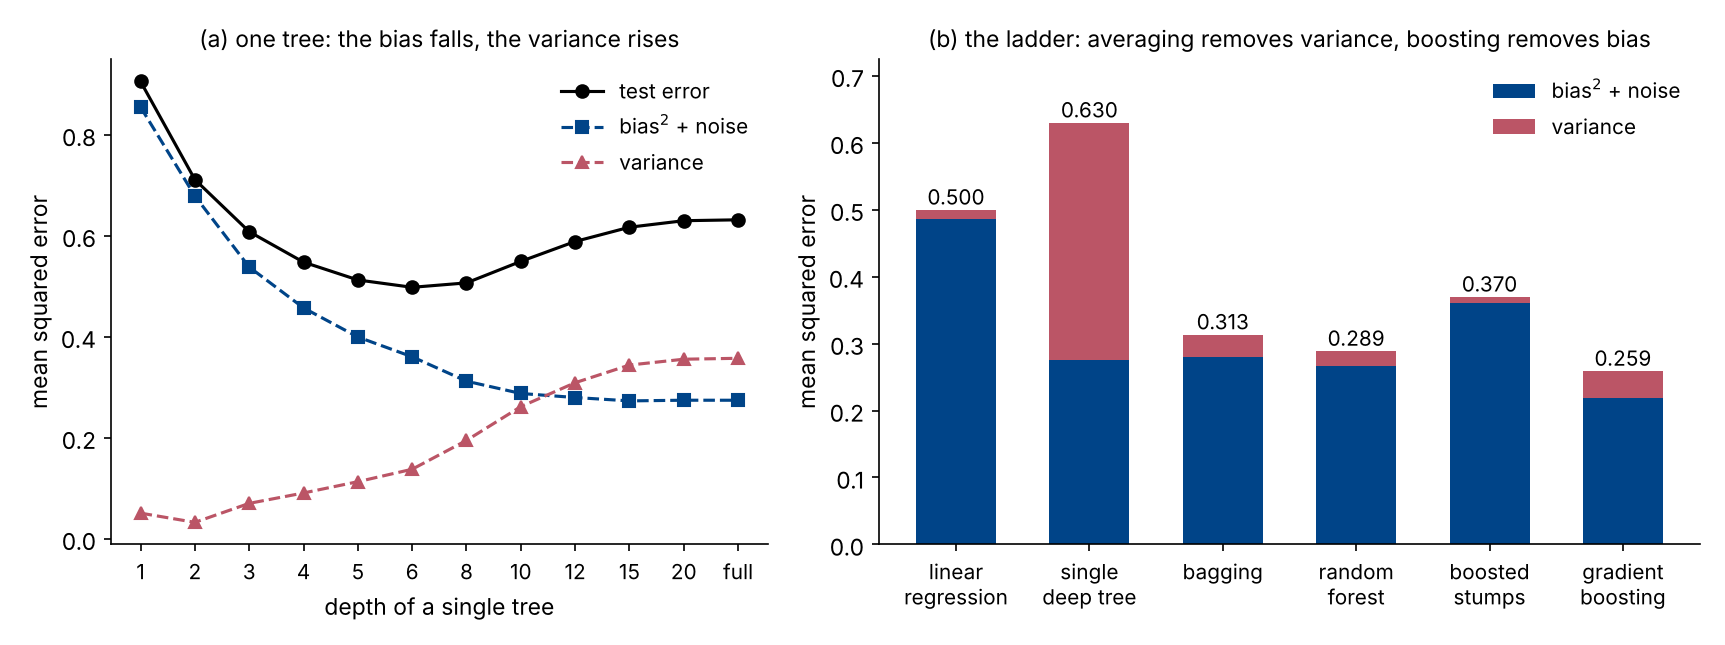

In [15]:
bv = bias_variance_housing(n_rep=30, n_train=3000, n_test=2000, B=50, fname="week48_housing_biasvar.png")
display(Image("week48_housing_biasvar.png"))

**The first lecture in six bars.**

* *One tree*: the depth trades bias for variance, and the best compromise
  (depth 6, error $0.498$) is no better than a straight line ($0.500$).
* *Bagging* keeps the bias of the deep tree ($0.275\to0.280$) and divides its
  variance by ten ($0.355\to0.034$) — what Eq. (7.16) promises, and nothing
  else. Solving $\rho\sigma^2+(1-\rho)\sigma^2/B=0.034$ with
  $\sigma^2\approx0.355$ and $B=50$ gives $\rho\approx0.08$: with infinitely
  many trees the variance would only fall to the floor
  $\rho\sigma^2\approx0.027$.
* *The forest* lowers the variance once more ($0.023$) by lowering $\rho$.
* *Boosted stumps* have the variance of a linear model ($0.009$) and much
  less bias ($0.361$ against $0.486$): an additive model, one feature at a
  time.
* *Boosting with depth 4* attacks the bias that averaging cannot touch
  ($0.219$) at a small price in variance. It wins because the bias was the
  larger term.

### 2.5 What has the boosted model learned?

Three importance measures — the impurity importance of the forest and of the
boosted model (the summed gains of the splits on a feature), and the
permutation importance of the boosted model (the drop in test $R^2$ when one
column is shuffled) — and the partial dependence of the boosted model on the
income, the occupancy and the position.

In [16]:
def fig_housing_learned(fitted, data, fname="week48_housing_learned.pdf"):
    """What the models have learned: (a) three importance measures, (b, c)
    the partial dependence of the boosted model on the median income and on
    the occupancy, (d) the two-dimensional partial dependence on the position."""
    from sklearn.inspection import permutation_importance, partial_dependence
    Xtr, Xte, ytr, yte, names = data
    rf = fitted["random forest, m = 3"]
    gb = [m for k, m in fitted.items() if k.startswith("gradient boosting, depth 6")][0]
    perm = permutation_importance(gb, Xte, yte, n_repeats=5, random_state=SEED, n_jobs=-1,
                                  scoring="r2")
    order = np.argsort(perm.importances_mean)
    print("\nImportances on the housing data (random forest impurity, gradient boosting impurity, "
          "permutation = drop in test R2 of gradient boosting):")
    for i in order[::-1]:
        print(f"  {names[i]:11s} {rf.feature_importances_[i]:.3f}  {gb.feature_importances_[i]:.3f}  "
              f"{perm.importances_mean[i]:.3f} +- {perm.importances_std[i]:.3f}")
    fig, ax = plt.subplots(1, 4, figsize=(12.5, 4.2), gridspec_kw={"width_ratios": [1.3, 0.9, 0.9, 1.15]})
    h = 0.27
    yy = np.arange(len(names))
    ax[0].barh(yy + h, rf.feature_importances_[order], height=h, color=GREEN, label="forest, impurity")
    ax[0].barh(yy, gb.feature_importances_[order], height=h, color=BLUE, label="boosting, impurity")
    ax[0].barh(yy - h, perm.importances_mean[order] / perm.importances_mean.sum(), height=h, color=RED,
               label="boosting, permutation")
    ax[0].set_yticks(yy)
    ax[0].set_yticklabels([names[i] for i in order], fontsize=10)
    ax[0].set_xlabel("importance (each normalised to sum 1)")
    ax[0].set_title("(a) three importance measures", fontsize=11)
    ax[0].legend(fontsize=9, frameon=False, loc="lower right")
    sub = Xtr[np.random.default_rng(SEED).choice(len(Xtr), 3000, replace=False)]
    pd_out = {}
    for a, feat, lab in [(ax[1], "MedInc", "median income"), (ax[2], "AveOccup", "persons per household")]:
        j = names.index(feat)
        pd = partial_dependence(gb, sub, [j], grid_resolution=60, percentiles=(0.02, 0.98), method="brute")
        a.plot(pd["grid_values"][0], pd["average"][0], color=BLUE, lw=1.6)
        a.set_xlabel(lab)
        a.set_ylabel("partial dependence")
        pd_out[feat] = (pd["grid_values"][0], pd["average"][0])
    ax[1].set_title("(b) monotone, saturating", fontsize=11)
    ax[2].set_title("(c) crowded is cheaper", fontsize=11)
    jl, jb = names.index("Longitude"), names.index("Latitude")
    pd = partial_dependence(gb, sub[:1000], [(jl, jb)], grid_resolution=30, percentiles=(0.0, 1.0),
                            method="brute")
    G = pd["average"][0].T
    gx, gy = pd["grid_values"][0], pd["grid_values"][1]
    edges = lambda g: np.r_[g[0] - (g[1] - g[0]) / 2, (g[1:] + g[:-1]) / 2, g[-1] + (g[-1] - g[-2]) / 2]
    count = np.histogram2d(Xtr[:, jl], Xtr[:, jb], bins=[edges(gx), edges(gy)])[0].T
    G = np.where(count > 0, G, np.nan)          # show the model only where there are districts
    im = ax[3].pcolormesh(gx, gy, G, cmap="viridis", shading="auto")
    fig.colorbar(im, ax=ax[3], fraction=0.046, pad=0.02)
    ax[3].set_xticks([-124, -122, -120, -118, -116])
    ax[3].set_xlabel("longitude")
    ax[3].set_ylabel("latitude")
    ax[3].set_title("(d) partial dependence on the position\n(cells with districts only)", fontsize=11)
    fig.tight_layout()
    save(fig, fname)
    g, a = pd_out["MedInc"]
    print(f"  partial dependence on MedInc: {a[0]:.2f} at {g[0]:.1f}  ->  {a[-1]:.2f} at {g[-1]:.1f}")
    g, a = pd_out["AveOccup"]
    print(f"  partial dependence on AveOccup: {a[0]:.2f} at {g[0]:.1f}  ->  {a[-1]:.2f} at {g[-1]:.1f}")
    return perm



Importances on the housing data (random forest impurity, gradient boosting impurity, permutation = drop in test R2 of gradient boosting):
  Latitude    0.125  0.101  1.592 +- 0.029
  Longitude   0.123  0.108  1.414 +- 0.036
  MedInc      0.400  0.541  0.446 +- 0.006


  AveOccup    0.126  0.134  0.132 +- 0.004
  AveRooms    0.099  0.033  0.069 +- 0.002
  HouseAge    0.055  0.046  0.043 +- 0.002
  AveBedrms   0.040  0.019  0.009 +- 0.001


  Population  0.032  0.018  0.003 +- 0.000


  partial dependence on MedInc: 1.45 at 1.3  ->  3.66 at 8.8
  partial dependence on AveOccup: 2.64 at 1.7  ->  1.78 at 4.9


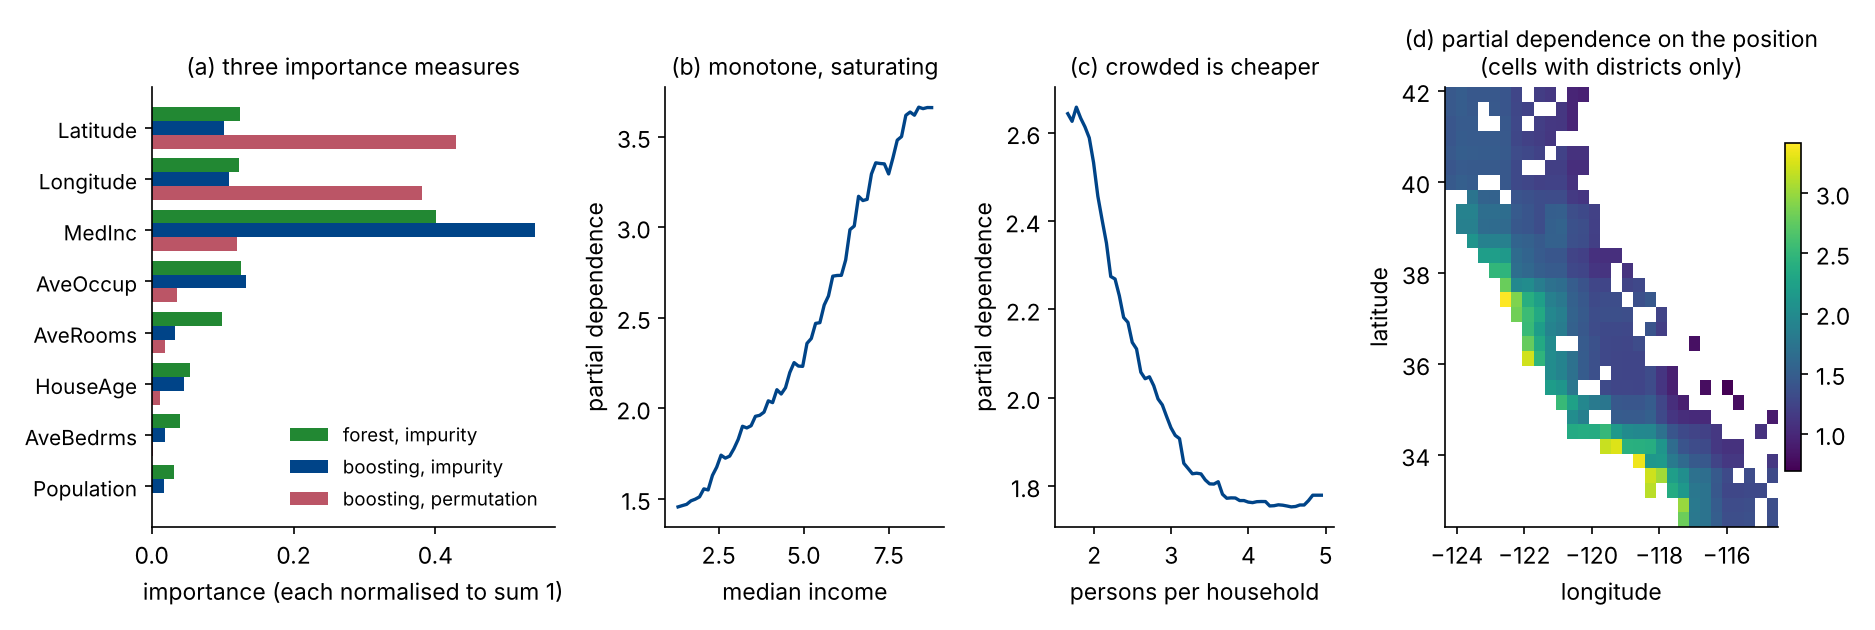

In [17]:
perm = fig_housing_learned(fitted_h, data_h, "week48_housing_learned.png")
display(Image("week48_housing_learned.png"))

The importances disagree. The impurity importance puts the income first
($0.54$ in the boosted model); the permutation importance puts latitude and
longitude first (a drop in $R^2$ of $1.59$ and $1.41$, against $0.45$ for the
income — a drop larger than one means worse than predicting the mean). The
position acts through the *pair*: shuffling one coordinate moves every
district to a wrong place. The partial dependence on the income is monotone
and flattens; crowded districts are cheaper; and panel (d) redraws the map of
Section 2.1, now with everything else held fixed. A model that cannot be read
as a tree can still be interrogated — but none of this is causal.

### 2.6 What to tune

| | the knobs (scikit-learn names) | more trees | start with |
|---|---|---|---|
| single tree | `max_depth`, `min_samples_leaf`, or prune with `ccp_alpha` | — | cross-validate the depth |
| bagging | `n_estimators` only | never hurts, saturates | 100–500 deep trees |
| random forest | `max_features` ($m$), then `min_samples_leaf` | never hurts, saturates | $m=\sqrt p$ or $p/3$; check the out-of-bag score |
| AdaBoost | `n_estimators`, `learning_rate`, depth of the weak learner | can overfit with noisy labels | stumps, a few hundred rounds |
| gradient boosting | `learning_rate` ($\nu$) and `n_estimators` ($M$) together; `max_depth`; `subsample` | overfits eventually: stop early | $\nu=0.05$–$0.1$, depth 3–6, early stopping |
| XGBoost | the same, plus `reg_lambda`, `gamma`, `colsample_bytree`, `min_child_weight` | overfits eventually: stop early | the defaults with early stopping, then depth and $\nu$ |

None of them needs scaling of the features; the linear and neural models in
the same comparison do — inside a pipeline.

## Part 3 — The semester in two figures

### 3.1 One function, all the methods

The noisy Runge function $f(x)=1/(1+25x^2)$ of Project 1 (200 training and
200 test points, noise variance $0.01$; the data of week 46), with one
representative of each block of the semester: ordinary least squares with a
polynomial of degree 10, Ridge regression at degree 20 with $\lambda$ chosen
by cross-validation, a neural network with two hidden layers, a single tree,
a random forest and gradient boosting.

In [18]:
def runge(x):
    return 1.0 / (1.0 + 25.0 * x**2)


def runge_data(n=200, noise=0.1, seed=SEED):
    """The Runge function on [-1, 1] with Gaussian noise (the data of week 46)."""
    rng = np.random.default_rng(seed)
    x = np.sort(rng.uniform(-1, 1, n))
    y = runge(x) + noise * rng.standard_normal(n)
    return x[:, None], y


def semester_models():
    """One representative per block of the semester.  Polynomial features are
    Legendre polynomials (well conditioned on [-1, 1])."""
    from sklearn.preprocessing import FunctionTransformer, StandardScaler
    from sklearn.linear_model import LinearRegression, RidgeCV
    from sklearn.pipeline import make_pipeline
    from sklearn.neural_network import MLPRegressor
    from sklearn.tree import DecisionTreeRegressor
    from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
    legendre = lambda p: FunctionTransformer(lambda X: np.polynomial.legendre.legvander(X[:, 0], p)[:, 1:])
    return {
        "OLS, polynomial of degree 10\n(weeks 34-35)": make_pipeline(legendre(10), LinearRegression()),
        "Ridge, degree 20, $\\lambda$ by cross-validation\n(weeks 35-36)":
            make_pipeline(legendre(20), RidgeCV(alphas=np.logspace(-6, 1, 30))),
        "neural network, 1-50-50-1, tanh\n(weeks 40-42)":
            make_pipeline(StandardScaler(), MLPRegressor(hidden_layer_sizes=(50, 50), activation="tanh",
                                                         solver="lbfgs", alpha=1e-3, max_iter=5000,
                                                         random_state=SEED)),
        "a single tree, depth 4\n(week 46)": DecisionTreeRegressor(max_depth=4, random_state=SEED),
        "random forest, 200 trees\n(week 46)": RandomForestRegressor(n_estimators=200, min_samples_leaf=3,
                                                                    random_state=SEED),
        "gradient boosting, 200 trees of depth 2\n(week 47)":
            GradientBoostingRegressor(max_depth=2, learning_rate=0.05, n_estimators=200, random_state=SEED),
    }


def fig_semester_runge(fname="week48_semester_runge.pdf"):
    X, y = runge_data(200)
    Xte, yte = runge_data(200, seed=SEED + 1)
    xg = np.linspace(-1, 1, 600)[:, None]
    models = semester_models()
    fig, axes = plt.subplots(2, 3, figsize=(11.5, 5.6), sharex=True, sharey=True)
    out = {}
    print("\nThe semester on the Runge function (200 train / 200 test, noise variance 0.01):")
    for a, (k, m) in zip(axes.ravel(), models.items()):
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            m.fit(X, y)
        mse = np.mean((m.predict(Xte) - yte)**2)
        grid = np.mean((m.predict(xg) - runge(xg[:, 0]))**2)
        out[k] = (mse, grid)
        print(f"  {k.splitlines()[0]:45s} test MSE {mse:.4f}   MSE against the true function {grid:.5f}")
        a.plot(X[:, 0], y, ".", color=GREY, ms=3, alpha=0.6)
        a.plot(xg[:, 0], runge(xg[:, 0]), color="black", lw=1, ls="--")
        a.plot(xg[:, 0], m.predict(xg), color=GREEN if "week 4" in k else BLUE, lw=1.7)
        a.set_title(f"{k}\ntest MSE {mse:.4f}", fontsize=10.5)
    for a in axes[1]:
        a.set_xlabel("$x$")
    for a in axes[:, 0]:
        a.set_ylabel("$y$")
    fig.tight_layout()
    save(fig, fname)
    return out



The semester on the Runge function (200 train / 200 test, noise variance 0.01):
  OLS, polynomial of degree 10                  test MSE 0.0133   MSE against the true function 0.00187
  Ridge, degree 20, $\lambda$ by cross-validation test MSE 0.0131   MSE against the true function 0.00114
  neural network, 1-50-50-1, tanh               test MSE 0.0118   MSE against the true function 0.00039
  a single tree, depth 4                        test MSE 0.0181   MSE against the true function 0.00516
  random forest, 200 trees                      test MSE 0.0150   MSE against the true function 0.00272


  gradient boosting, 200 trees of depth 2       test MSE 0.0146   MSE against the true function 0.00254


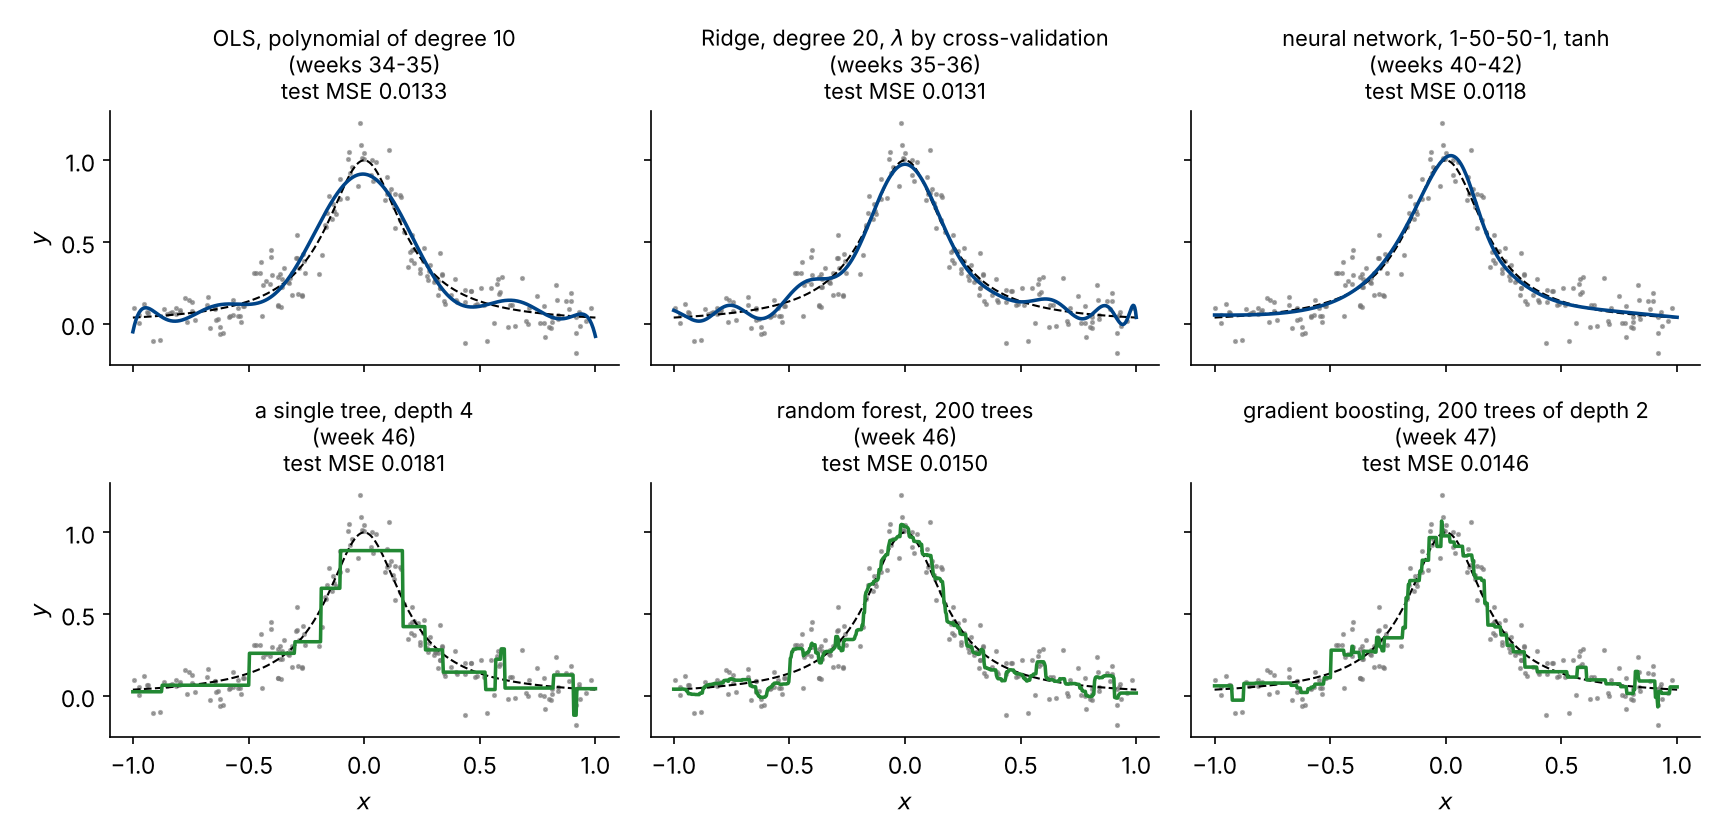

In [19]:
out_runge = fig_semester_runge("week48_semester_runge.png")
display(Image("week48_semester_runge.png"))

A smooth target favours smooth models: the network comes closest to the
noise floor ($0.0118$ against $0.0100$), the polynomials follow, and the sums
of trees remain staircases ($0.0146$–$0.0150$; a single tree $0.0181$). On the
housing data the order was the opposite.

### 3.2 The bias–variance tradeoff, four times

Forty equally spaced points, the noise redrawn 100 times (the fixed design of
week 36). The test error against four complexity knobs: the polynomial degree
(OLS), the Ridge parameter at degree 30, the depth of a tree, and the number
of boosting rounds. Complexity grows to the right in every panel; dotted
curves are training errors.

In [20]:
def u_curves(n=40, noise=0.1, n_rep=100, fname="week48_ucurves.pdf"):
    """The test error against four complexity knobs, averaged over n_rep
    training sets: the polynomial degree (OLS), the Ridge parameter at degree
    30, the depth of a tree and the number of boosting rounds.  Fixed design
    as in week 36: n equally spaced points, only the noise is redrawn; the
    test error is measured against the true function on a fine grid, plus
    the noise variance.  Dotted: training error."""
    from sklearn.linear_model import LinearRegression, Ridge
    from sklearn.tree import DecisionTreeRegressor
    from sklearn.ensemble import GradientBoostingRegressor
    rng = np.random.default_rng(SEED)
    xt = np.linspace(-1, 1, 400)
    yt_true = runge(xt)
    leg = lambda x, p: np.polynomial.legendre.legvander(x, p)[:, 1:]
    degrees = np.arange(1, 31)
    lambdas = np.logspace(-8, 1, 19)
    depths = np.arange(1, 11)
    Mmax = 300
    tr = {k: 0.0 for k in "abcd"}
    te = {k: 0.0 for k in "abcd"}
    for r in range(n_rep):
        x = np.linspace(-1, 1, n)
        y = runge(x) + noise * rng.standard_normal(n)
        e_tr, e_te = [], []
        for p in degrees:
            m = LinearRegression().fit(leg(x, p), y)
            e_tr.append(np.mean((m.predict(leg(x, p)) - y)**2))
            e_te.append(np.mean((m.predict(leg(xt, p)) - yt_true)**2) + noise**2)
        tr["a"] += np.array(e_tr) / n_rep
        te["a"] += np.array(e_te) / n_rep
        e_tr, e_te = [], []
        for lam in lambdas:
            m = Ridge(alpha=lam).fit(leg(x, 30), y)
            e_tr.append(np.mean((m.predict(leg(x, 30)) - y)**2))
            e_te.append(np.mean((m.predict(leg(xt, 30)) - yt_true)**2) + noise**2)
        tr["b"] += np.array(e_tr) / n_rep
        te["b"] += np.array(e_te) / n_rep
        e_tr, e_te = [], []
        for d in depths:
            m = DecisionTreeRegressor(max_depth=int(d)).fit(x[:, None], y)
            e_tr.append(np.mean((m.predict(x[:, None]) - y)**2))
            e_te.append(np.mean((m.predict(xt[:, None]) - yt_true)**2) + noise**2)
        tr["c"] += np.array(e_tr) / n_rep
        te["c"] += np.array(e_te) / n_rep
        m = GradientBoostingRegressor(max_depth=2, learning_rate=0.3, n_estimators=Mmax).fit(x[:, None], y)
        tr["d"] += np.array([np.mean((f - y)**2) for f in m.staged_predict(x[:, None])]) / n_rep
        te["d"] += np.array([np.mean((f - yt_true)**2) + noise**2 for f in m.staged_predict(xt[:, None])]) / n_rep
    fig, ax = plt.subplots(1, 4, figsize=(11.5, 4.0), sharey=True)
    panels = [("a", degrees, "polynomial degree (OLS)", False, "(a) weeks 34-36"),
              ("b", lambdas, "Ridge parameter $\\lambda$ (degree 30)", True, "(b) week 35"),
              ("c", depths, "depth of a tree", False, "(c) week 46"),
              ("d", np.arange(1, Mmax + 1), "boosting rounds $M$ ($\\nu=0.3$)", True, "(d) week 47")]
    best = {}
    for a, (k, xs, lab, logx, title) in zip(ax, panels):
        a.plot(xs, te[k], "-", color=BLUE, lw=1.7, label="test")
        a.plot(xs, tr[k], ":", color=RED, lw=1.5, label="training")
        i = int(np.argmin(te[k]))
        best[k] = (xs[i], te[k][i])
        a.plot(xs[i], te[k][i], "o", color=BLUE)
        a.axhline(noise**2, color=GREY, lw=0.8, ls="--")
        if logx:
            a.set_xscale("log")
        a.set_xlabel(lab)
        a.set_title(title, fontsize=11)
        a.set_yscale("log")
        a.set_ylim(2e-3, 0.2)
    ax[1].invert_xaxis()                       # complexity grows to the right in every panel
    ax[0].set_ylabel("mean squared error")
    ax[0].legend(fontsize=10, frameon=False, loc="lower left")
    ax[0].text(degrees[-1], noise**2 * 0.82, "noise $\\sigma^2$", color=GREY, fontsize=9.5, ha="right", va="top")
    fig.tight_layout()
    save(fig, fname)
    print(f"\nU-curves on the Runge function (n = {n} equally spaced points, {n_rep} noise draws, "
          f"noise variance {noise**2:.2f}):")
    print(f"  OLS: best degree {best['a'][0]}, test error {best['a'][1]:.4f}; degree 30: {te["a"][-1]:.4f}")
    print(f"  Ridge, degree 30: best lambda {best['b'][0]:.1e}, test error {best['b'][1]:.4f}; "
          f"lambda=1e-8: {te['b'][0]:.4f}; lambda=10: {te['b'][-1]:.4f}")
    print(f"  tree: best depth {best['c'][0]}, test error {best['c'][1]:.4f}; depth 10: {te['c'][-1]:.4f}")
    print(f"  boosting (depth 2, nu 0.3): best M {best['d'][0]}, test error {best['d'][1]:.4f}; "
          f"M = {Mmax}: {te['d'][-1]:.4f}")
    return best, tr, te



U-curves on the Runge function (n = 40 equally spaced points, 100 noise draws, noise variance 0.01):
  OLS: best degree 12, test error 0.0138; degree 30: 1873.4780
  Ridge, degree 30: best lambda 3.2e-01, test error 0.0151; lambda=1e-8: 1788.7345; lambda=10: 0.0454
  tree: best depth 5, test error 0.0197; depth 10: 0.0206
  boosting (depth 2, nu 0.3): best M 12, test error 0.0152; M = 300: 0.0206


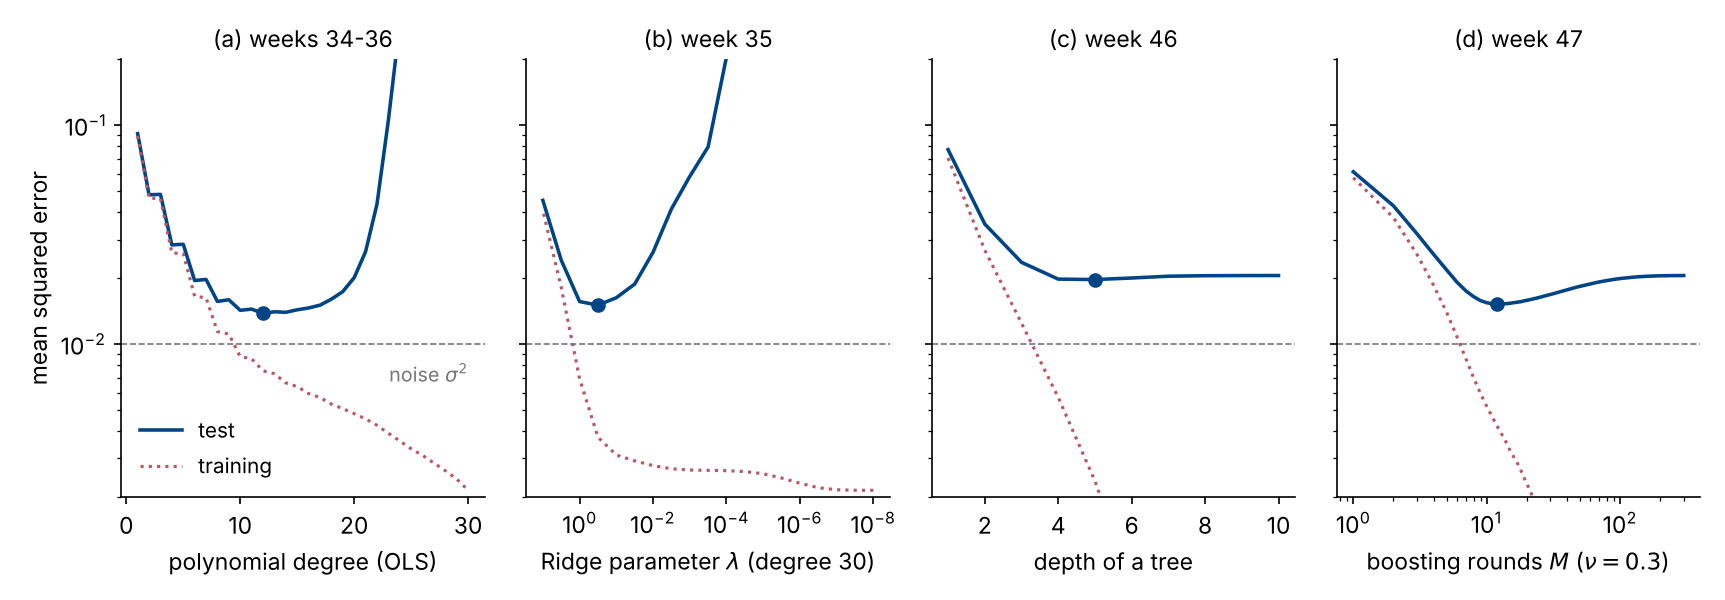

In [21]:
best, tr, te = u_curves(n=40, noise=0.1, n_rep=100, fname="week48_ucurves.png")
display(Image("week48_ucurves.png"))

The training error always falls; the test error,
$\mathbb{E}[(y-\tilde y)^2]=\mathrm{bias}^2+\mathrm{variance}+\sigma^2$
(Eq. 2.52), has a minimum. What differs between the methods is the price of
going too far: a polynomial of high degree and a vanishing $\lambda$ are
catastrophic, a fully grown tree and too many boosting rounds are bounded —
they reproduce the noise and cost at most another $\sigma^2$. That is why
averaging deep trees works. In a neural network the same knobs are the number
of hidden nodes and layers (degree, depth), the $L_2$ penalty ($\lambda$) and
the number of epochs (boosting rounds), with the learning rate in the role of
$\nu$.

### 3.3 The semester week by week

| week | Monday lecture | book | project |
|---|---|---|---|
| 34 | Linear regression: the normal equations, statistics of the estimator | 3.1–3.7 | |
| 35 | Ridge and Lasso regression, Gauss–Markov | 3.8–3.11 | |
| 36 | The bias–variance tradeoff, bootstrap and cross-validation | Ch. 2, 3.14 | |
| 37 | Gradient descent and momentum | 4.1–4.6 | |
| 38 | Automatic differentiation, AdaGrad, RMSProp, Adam, SGD | Ch. 4 | |
| 39 | SGD once more, logistic regression, the perceptron | Ch. 5 | |
| 40 | From logistic regression to the first neural network | Ch. 8 | |
| 41 | Backpropagation in general, a neural network of our own, MNIST | Ch. 8 | **Project 1**, October 5 |
| 42 | Neural networks for differential equations, PINNs | Ch. 9 | |
| 43 | The Poisson equation three ways; reading a classifier; first CNNs | Ch. 9, 10 | |
| 44 | Convolutional neural networks; cross-validation of a network | Ch. 10 | |
| 45 | Recurrent neural networks | Ch. 11 | |
| 46 | Decision trees, bagging and random forests | 7.1–7.10 | **Project 2**, November 9 |
| 47 | Boosting: AdaBoost, gradient boosting, XGBoost | 7.11–7.16 | |
| 48 | Summary | Ch. 18 | **Project 3**, December 14 |

### 3.4 Four threads

**1. Every method is the same four choices** — a model, a cost function, an
optimizer, and a way to control the complexity:

| | model | cost function | how it is minimised | complexity knob |
|---|---|---|---|---|
| OLS | $X\theta$ | mean squared error | closed form: normal equations, SVD | number of features |
| Ridge, Lasso | $X\theta$ | MSE $+\lambda\Vert\theta\Vert_2^2$ or $+\lambda\Vert\theta\Vert_1$ | closed form (Ridge), gradient methods (Lasso) | $\lambda$ |
| logistic regression | $\sigma(x^T\theta)$, softmax | cross entropy | gradient descent, SGD, Newton | $\lambda$ |
| neural networks (dense, CNN, RNN) | layers of affine maps and activations | MSE or cross entropy; the residual of an equation (PINNs) | backpropagation + SGD or Adam | width, depth, $\lambda$, epochs |
| decision tree | a constant in each of $J$ boxes | Gini, entropy or MSE | greedy recursive splitting | depth, number of leaves |
| bagging, random forest | an average of deep trees | that of the trees | bootstrap and average | $m$ |
| boosting | a sum of shallow trees | exponential, logistic, squared loss | gradient descent in function space | $M$, $\nu$, depth |

**2. The bias–variance tradeoff** (Section 3.2 above, and Section 2.4 for the
ensembles).

**3. Gradients, all the way down.** Set the gradient to zero (the normal
equations); follow it (gradient descent, momentum, SGD, Adam); let the
computer derive it (automatic differentiation, of which backpropagation is
the reverse mode); differentiate with respect to the input (networks for
differential equations); differentiate with respect to the function (gradient
boosting).

**4. Assessing a model honestly.** Training data to fit, validation data or
cross-validation to choose hyperparameters, test data once; every
data-dependent step inside the fold; the right number for the question (MSE
and $R^2$; accuracy next to the majority class, the confusion matrix, ROC and
AUC, cross entropy); and an uncertainty on every number — a difference
between two methods smaller than the spread over folds or seeds is not a
result.

### 3.5 The insights we want you to have after this course

1. **A method is four choices**: a model, a cost function, an optimizer and
   a way to control the complexity. You can take any new method apart in this
   way.
2. **The cost function is derived, not chosen.** The squared error and the
   cross entropy are maximum likelihood under a model for the noise, and the
   output activation follows from it.
3. **Bias and variance are traded, never both removed.** Every method has a
   knob, the test error has a minimum, and the training error does not tell
   you where it is.
4. **The chain rule is enough.** Gradients drive almost all training;
   automatic differentiation computes them, backpropagation is one instance
   of it — and a gradient can always be checked.
5. **Conditioning decides how hard the optimization is.** The learning rate
   is limited by the largest curvature; scaling the data, momentum and
   adaptive methods all address the same problem.
6. **Structure is the cheapest prior.** Convolutions for images, recurrence
   for sequences, the equation for a physical system, boxes for a table:
   build what you know about the data into the model.
7. **A number without an error bar and a baseline is not a result.**
   Resample, keep the test set for the end, and compare with the simplest
   model that could work.
8. **None of it is a black box.** You have written regression, gradient
   descent and a neural network yourselves and checked them against the
   libraries. Use that when you read a paper, a code — or the output of a
   language model.

These eight, more than any single algorithm, are what we hope stays with you.
The four threads of Section 3.4 are insights 1, 3, 4 and 7.

### 3.6 The neural network as a building block: transformers, large language models, reinforcement learning

A neural network is a differentiable function with trainable parameters,
$f(\boldsymbol{x};\boldsymbol{\theta})$, fitted by backpropagation and a
gradient method to a cost function. The more advanced methods keep all of
this; they change *what the network represents* and *where the training
signal comes from*.

| | what the network represents | the training signal | what you already know of it |
|---|---|---|---|
| this course | a regression function, class probabilities, the solution of an equation | labelled data: MSE, cross entropy; the residual of the equation | everything: weeks 39–45 |
| transformers | a map from a whole sequence to a sequence: attention layers and dense layers, stacked | as for any network: a cost function and backpropagation | dense layers, softmax, backpropagation, Adam; what recurrent networks struggle with (week 45) |
| large language models | the probability of the next token given the text so far — a transformer | the text itself: cross entropy of the next token, no labels needed | multiclass classification with softmax, minibatch SGD, weight decay, validation |
| reinforcement learning | a policy (probabilities of actions) or the value of a state and an action | rewards collected by acting in an environment | softmax output and gradient ascent; regression with the squared error; CNNs that read the state |
| generative models (diffusion, VAEs, GANs) | a probability distribution to sample from | the data themselves; in diffusion models a regression on added noise | MSE regression, maximum likelihood, the bias–variance tradeoff |

**Transformers** (Chapter 13). One block is an attention layer followed by
the dense network of week 41. Attention is a softmax-weighted average over
the positions of the sequence,
$$\mathrm{Attention}(Q,K,V)=\mathrm{softmax}\Big(\frac{QK^T}{\sqrt{d}}\Big)V,$$
with $Q$, $K$, $V$ affine maps of the input. All positions are treated in
parallel — there is no backpropagation through time.

**Large language models.** A deep transformer trained as a classifier: the
classes are the some $10^5$ tokens of a vocabulary, the cost function is the
cross entropy $-\sum_t\log p(x_t\,|\,x_1,\dots,x_{t-1};\boldsymbol{\theta})$,
minimised with minibatches and a variant of Adam. New is the scale, not the
principle.

**Reinforcement learning.** An agent acts, the environment answers with a new
state and a reward. *Value-based*: a network $Q(s,a;\boldsymbol{\theta})$ is
fitted by least squares to "reward plus discounted value of the next state" —
a regression; the network that learned Atari games from the screen was a
convolutional network trained with RMSProp. *Policy-based*: a softmax output
gives the probabilities of the actions, and the parameters follow the
gradient of the expected reward. AlphaGo combined both, with convolutional
networks and a tree search. A language model that chooses actions — runs a
code, queries a database — and receives the result is a policy in a
reinforcement-learning loop: agentic AI.

**Where to continue.** FYS5429 (*Advanced machine learning and data analysis
for the physical sciences*) addresses the topics this course has left out,
except support vector machines (Chapter 6 of the book); the new course
FYS4425 covers reinforcement learning and agentic AI for the physical
sciences; FYS5419 covers quantum computing and quantum machine learning.

## Part 4 — One data set, the whole semester: MNIST

Softmax regression, a random forest and histogram gradient boosting on the
raw pixels of the full MNIST set (60 000 training and 10 000 test images), to
put next to our own dense network of week 41 (784–100–10, test accuracy
$0.976$) and the convolutional network of week 44 ($0.991$). The file
`mnist.npz` (see Project 2 for the download link) must be in this folder.
This cell takes a few minutes — the boosting alone about three on two
cores; set `RUN_MNIST = False` to skip it.

In [22]:
def load_mnist():
    for path in ("mnist.npz", "../BookPrograms/chapter10_convolutional_networks/mnist.npz"):
        if os.path.exists(path):
            d = np.load(path)
            return (d["x_train"].reshape(60000, -1) / 255.0, d["y_train"],
                    d["x_test"].reshape(10000, -1) / 255.0, d["y_test"])
    raise FileNotFoundError("mnist.npz not found (see Project 2 for the download link)")


def mnist_trees(B=100, M=100):
    """A random forest and histogram gradient boosting on the raw pixels of
    the full MNIST set (60 000 / 10 000), to compare with the numbers of
    weeks 39-44."""
    from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
    from sklearn.linear_model import LogisticRegression
    Xtr, ytr, Xte, yte = load_mnist()
    out = {}
    print("\nMNIST, raw pixels, 60 000 train / 10 000 test:")
    t0 = time.time()
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        m = LogisticRegression(max_iter=100).fit(Xtr, ytr)
    out["softmax regression"] = (m.score(Xte, yte), time.time() - t0)
    print(f"  softmax (multinomial logistic) regression  test accuracy {out['softmax regression'][0]:.4f} "
          f"({out['softmax regression'][1]:.0f} s)")
    t0 = time.time()
    m = RandomForestClassifier(n_estimators=B, n_jobs=-1, random_state=SEED).fit(Xtr, ytr)
    out["random forest"] = (m.score(Xte, yte), time.time() - t0)
    print(f"  random forest, {B} trees                    test accuracy {out['random forest'][0]:.4f} "
          f"({out['random forest'][1]:.0f} s)")
    t0 = time.time()
    m = HistGradientBoostingClassifier(max_iter=M, learning_rate=0.1, max_leaf_nodes=31,
                                       random_state=SEED).fit(Xtr, ytr)
    out["gradient boosting"] = (m.score(Xte, yte), time.time() - t0)
    print(f"  histogram gradient boosting, {M} rounds     test accuracy {out['gradient boosting'][0]:.4f} "
          f"({out['gradient boosting'][1]:.0f} s)")
    return out


In [23]:
RUN_MNIST = True
if RUN_MNIST:
    out_mnist = mnist_trees(B=100, M=100)


MNIST, raw pixels, 60 000 train / 10 000 test:


  softmax (multinomial logistic) regression  test accuracy 0.9258 (18 s)


  random forest, 100 trees                    test accuracy 0.9694 (14 s)


  histogram gradient boosting, 100 rounds     test accuracy 0.9779 (176 s)


| method (raw pixels) | test accuracy | week |
|---|---|---|
| softmax regression | 0.926 | today |
| our own network, 784–100–10, 20 epochs | 0.976 | 41 |
| random forest, 100 trees | 0.969 | today |
| histogram gradient boosting, 100 rounds | 0.978 | today |
| convolutional network (PyTorch, Keras), 5 epochs | 0.991 | 44 |

Every non-linear method removes some 60 to 70 % of the errors of the linear
one. Trees on raw pixels do as well as a dense network — neither knows that
pixel $(i,j)$ is next to pixel $(i,j+1)$. The method that builds the structure
of the data into the model, locality and shared filters, removes more than
half of the remaining errors.

## Summary

* A tree is a set of boxes found by a greedy search; its weakness is
  variance. Averaging deep trees (bagging, random forests) removes variance
  down to the floor $\rho\sigma^2$ of Eq. (7.16) and leaves the bias;
  boosting adds shallow trees fitted to the gradient of a loss, removes bias,
  and must be stopped. On the housing data all of this was measured: variance
  $0.355\to0.034\to0.023$ by averaging, bias plus noise $0.28\to0.22$ by
  boosting.
* Cancer data: the linear model wins. Housing data: boosted trees win. Runge
  function: smooth models win. Images: convolutions win. There is no best
  method, only a best method for a data set — and we find it by comparing
  honestly, against a simple baseline, on data the models have not seen, with
  error bars.
* The same loop for every new problem: identify the problem type, look at the
  data, start with the simplest model that fits, look at the data again, and
  go back to the earliest possible point.